In [2]:

%cd ..

from pathlib import Path
print(Path.cwd())

import numpy as np
import matplotlib.pyplot as plt

from hardware import ammeter, ammeter_uncertainty, gaussmeter, gaussmeter_uncertainty, horizontal_coils, vertical_coils, modulation_coils, horizontal_coils_uncertainty, vertical_coils_uncertainty, modulation_coils_uncertainty
from scope_header import DSOX1204G, self_test, load_waveforms


plt.rcParams.update({
    "font.sans-serif": ["Cabin", "Libertinus Sans", "DejaVu Sans"],
    "font.serif": ["Libertinus Serif"],
    "font.family": "sans-serif",
    "font.style": "normal",
    "font.weight": "normal",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelweight": "normal",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
    "legend.title_fontsize": 14,
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "mathtext.fontset": "cm",
    "mathtext.default": "it",
    "axes.unicode_minus": False,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",
})
%matplotlib inline

from scipy.optimize import curve_fit
from scipy import signal

# scope = DSOX1204G()


c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code
c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code


Text(0, 0.5, 'Transmission (arb. units)')

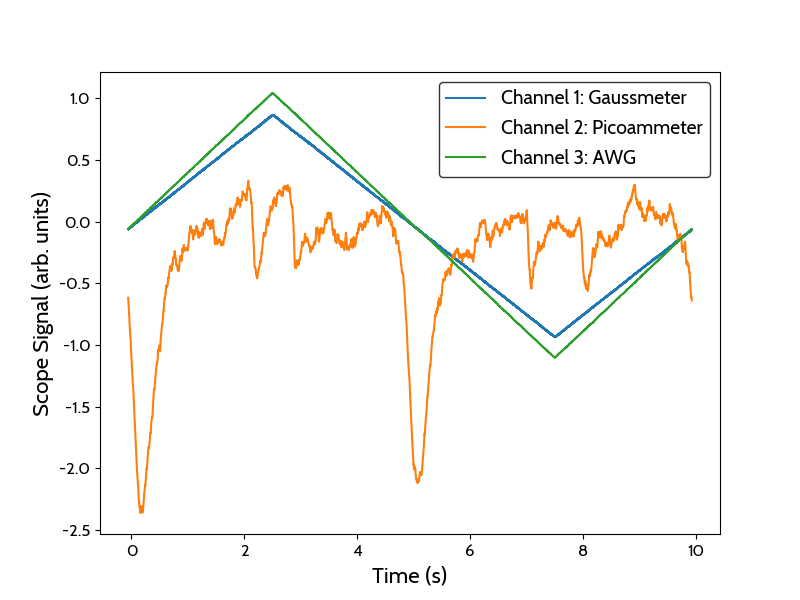

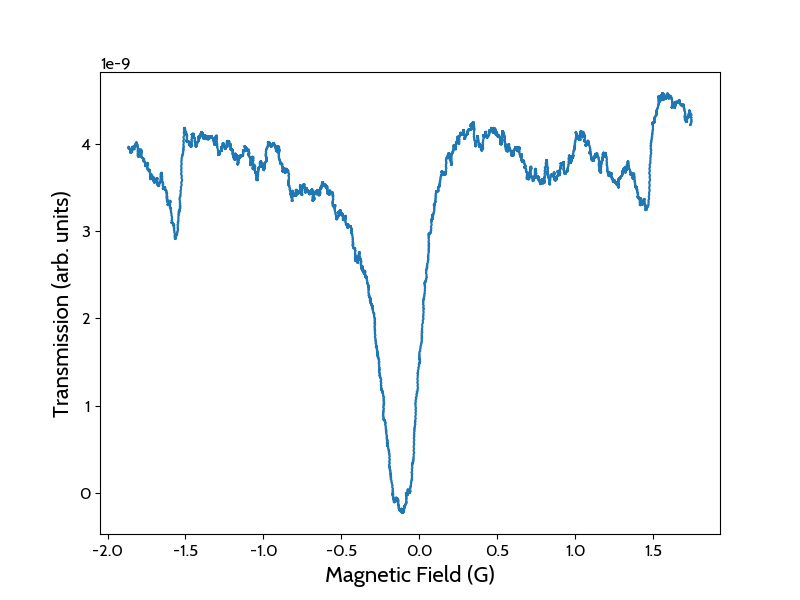

In [30]:
# 650 kHz
data = load_waveforms("data/23/test_40.npz")
t, V1, V2, V3 = data[1][0], data[1][1], data[2][1], data[3][1]


N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

mask = (t > 2.5) & (t < 7.5)

field = gaussmeter(V1[mask]*1e3)
transmission = ammeter(V2[mask]*1e3)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(field, transmission, label='Transmission vs Field', color='tab:blue')
ax.set_xlabel('Magnetic Field (G)')
ax.set_ylabel('Transmission (arb. units)')

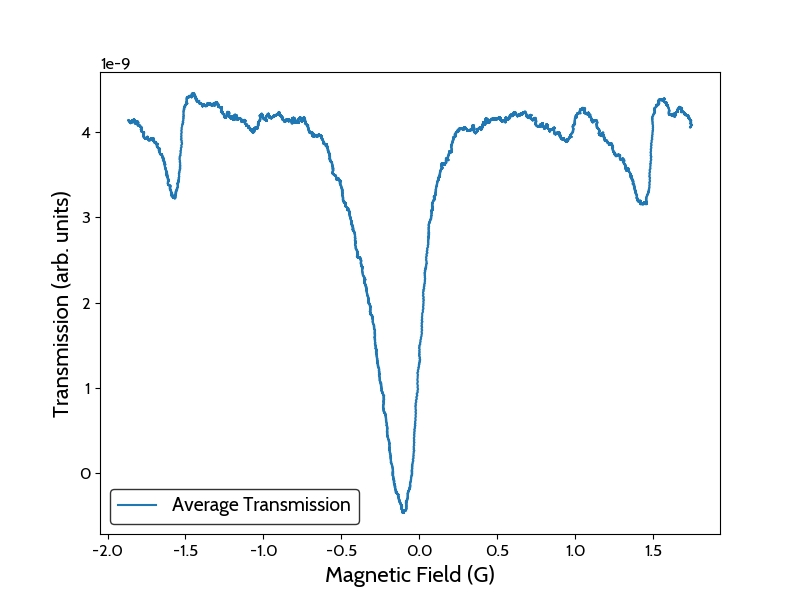

In [31]:
data = load_waveforms("data/23/test_40.npz")

t, V1, V2, V3 = data[1][0], data[1][1], data[2][1], data[3][1]
N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')


mask = (t > 2.5) & (t < 7.5)

field = gaussmeter(V1[mask]*1e3)
transmission = ammeter(V2[mask]*1e3)

transmissions = []
for data_num in range(36, 41):
    data = load_waveforms(f"data/23/test_{data_num}.npz")
    t, V1, V2, V3 = data[1][0], data[1][1], data[2][1], data[3][1]
    N = 400
    V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
    V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

    transmissions.append(ammeter(V2[mask]*1e3))

transmissions = np.array(transmissions)
np.mean(transmissions, axis=0)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(field, np.mean(transmissions, axis=0), label='Average Transmission', color='tab:blue')
ax.set_xlabel('Magnetic Field (G)')
ax.set_ylabel('Transmission (arb. units)')
ax.legend()
